# Test 04 — 第一次预测

左图显示粒子沉积到二维网格的密度，右图显示预测后粒子的三分量速度。z 速度因 z 电场增加，但 z 位置保持不变。

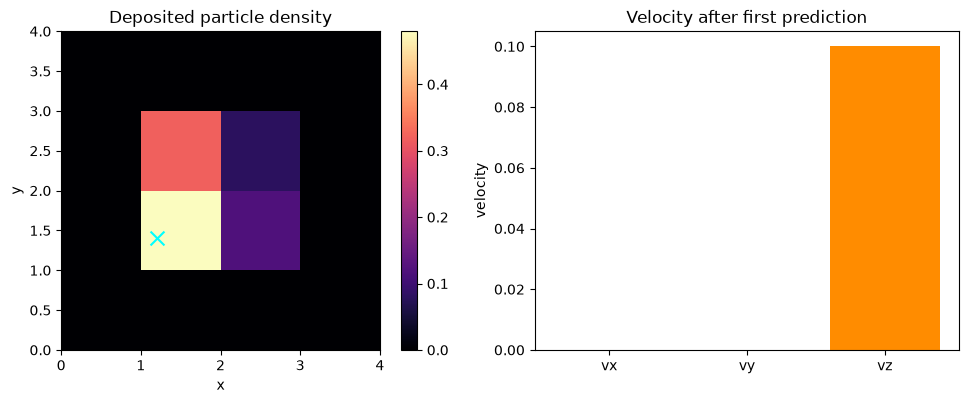

First prediction passed; z position: 7.0 | z velocity: 0.1


In [1]:
import os, sys
from pathlib import Path
module_dir = os.environ.get('BORIS_MODULE_DIR')
if module_dir is None:
    for parent in (Path.cwd(), *Path.cwd().parents):
        for candidate in (parent / 'build', parent / 'boris_cpp' / 'build'):
            if list(candidate.glob('boris_cpp*.so')): module_dir = str(candidate); break
        if module_dir: break
sys.path.insert(0, module_dir or '../build')
import matplotlib.pyplot as plt
import boris_cpp as boris
%matplotlib inline

grid = boris.PeriodicGrid(boris.Vec3(0,0,0), boris.Vec3(4,4,0), (4,4,1))
data = boris.PredictionInput()
data.electric = [boris.Vec3(0,0,1) for _ in range(grid.size())]
data.magnetic = [boris.Vec3(0,0,0) for _ in range(grid.size())]
data.particles = [boris.Particle(boris.Vec3(1.2,1.4,7), boris.Vec3(0,0,0), 1, 1)]
result = boris.predict_first(grid, data, 0.1)
particle = result.particles_next[0]
assert len(result.magnetic_next) == grid.size()
assert abs(particle.velocity.z - 0.05) < 1e-12
assert particle.position.z == 7
assert abs(sum(result.density_next) - 1.0) < 1e-12

density = [result.density_next[grid.index(i,j,0)] for j in range(4) for i in range(4)]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
image = axes[0].imshow([density[j*4:(j+1)*4] for j in range(4)], origin='lower', extent=(0,4,0,4), cmap='magma')
axes[0].scatter(particle.position.x, particle.position.y, color='cyan', marker='x', s=100)
axes[0].set(title='Deposited particle density', xlabel='x', ylabel='y'); fig.colorbar(image, ax=axes[0])
axes[1].bar(['vx','vy','vz'], [particle.velocity.x, particle.velocity.y, particle.velocity.z], color=['steelblue','steelblue','darkorange'])
axes[1].set(title='Velocity after first prediction', ylabel='velocity')
plt.tight_layout(); plt.show()
print('First prediction passed; z position:', particle.position.z, '| z velocity:', particle.velocity.z)